۱. وارد کردن کتابخانه ها و ماژول های مورد نیاز

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_style("whitegrid")
OUT_DIR = "outputs"
import os; os.makedirs(OUT_DIR, exist_ok=True)

online_retail = fetch_ucirepo(id=352)
df_raw = online_retail.data.original.copy()

print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
print("Dtypes:\n", df_raw.dtypes)

Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Dtypes:
 InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


سؤال ۱: چند سطر و چند ستون در دیتاست وجود دارد؟

In [2]:
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

Rows: 541,909
Columns: 8


سؤال ۲: نام تمام ستون‌ها چیست؟


In [3]:
for i, col in enumerate(df_raw.columns, 1):
    print(f"{i}. {col}")

1. InvoiceNo
2. StockCode
3. Description
4. Quantity
5. InvoiceDate
6. UnitPrice
7. CustomerID
8. Country


سؤال ۳: نوع داده هر ستون چیست؟


In [4]:
dtype_table = pd.DataFrame({
    "Column": df_raw.columns,
    "Dtype": df_raw.dtypes.astype(str).values,
})
print(dtype_table.to_string(index=False))

     Column   Dtype
  InvoiceNo     str
  StockCode     str
Description     str
   Quantity   int64
InvoiceDate     str
  UnitPrice float64
 CustomerID float64
    Country     str


سؤال ۴: برای هر ستون تعیین کنید: عددی / دسته‌ای / دودویی / زمانی.


In [5]:
def observe_type(series, name):
    if pd.api.types.is_bool_dtype(series):
        return "دودویی"
    if pd.api.types.is_numeric_dtype(series):
        if name in ["CustomerID"]:
            return "شناسه (عددی-گسسته)"
        return "عددی"
    if str(series.dtype) == "object":
        if name == "InvoiceDate":
            return "تاریخ (اما ذخیره‌شده به‌صورت رشته)"
        if name in ["InvoiceNo", "StockCode"]:
            return "شناسه (دسته‌ای با کاردینالیتی بالا)"
        if series.nunique(dropna=True) <= 2:
            return "دودویی"
        return "دسته‌ای"
    return "نامشخص"

type_table = pd.DataFrame({
    "Column": df_raw.columns,
    "Observed_Type": [observe_type(df_raw[c], c) for c in df_raw.columns],
    "N_Unique": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
})
print(type_table.to_string(index=False))

     Column      Observed_Type  N_Unique
  InvoiceNo             نامشخص     25900
  StockCode             نامشخص      4070
Description             نامشخص      4223
   Quantity               عددی       722
InvoiceDate             نامشخص     23260
  UnitPrice               عددی      1630
 CustomerID شناسه (عددی-گسسته)      4372
    Country             نامشخص        38


سوال ۵: در هر ستون چه مقدار مقادیر خالی وجود دارد؟


In [6]:
null_count = df_raw.isnull().sum()
null_table = pd.DataFrame({
    "Column": df_raw.columns,
    "Null_Count": null_count.values,
    "Null_Percent": (null_count / len(df_raw) * 100).round(2).values
}).sort_values("Null_Count", ascending=False)
print(null_table.to_string(index=False))

     Column  Null_Count  Null_Percent
 CustomerID      135080         24.93
Description        1454          0.27
  StockCode           0          0.00
  InvoiceNo           0          0.00
   Quantity           0          0.00
InvoiceDate           0          0.00
  UnitPrice           0          0.00
    Country           0          0.00


سؤال ۶: درصد داده‌های گمشده هر ستون چقدر است؟


In [7]:
missing_pct = (df_raw.isnull().sum() / len(df_raw) * 100).round(3)
print(missing_pct[missing_pct > 0])

Description     0.268
CustomerID     24.927
dtype: float64


سؤال ۷: آیا رکورد تکراری وجود دارد؟


In [8]:
dup_count_raw = df_raw.duplicated().sum()
print("Duplicate rows (raw):", dup_count_raw)

Duplicate rows (raw): 5268


سؤال ۸ : اگر رکورد تکراری وجود دارد، چند عدد و چند درصد؟


In [9]:
dup_pct_raw = dup_count_raw / len(df_raw) * 100
print(f"Duplicate count: {dup_count_raw:,}")
print(f"Duplicate percent: {dup_pct_raw:.3f}%")

Duplicate count: 5,268
Duplicate percent: 0.972%


سؤال ۹ : آمار توصیفی کامل ویژگی‌های عددی.


In [10]:
numeric_raw = ["Quantity", "UnitPrice"]
desc = df_raw[numeric_raw].describe(percentiles=[.05, .25, .5, .75, .95, .99]).T
desc["skew"] = df_raw[numeric_raw].skew()
desc["kurtosis"] = df_raw[numeric_raw].kurtosis()
print(desc.round(2))

              count  mean     std       min    5%   25%   50%    75%    95%  \
Quantity   541909.0  9.55  218.08 -80995.00  1.00  1.00  3.00  10.00  29.00   
UnitPrice  541909.0  4.61   96.76 -11062.06  0.42  1.25  2.08   4.13   9.95   

             99%      max    skew   kurtosis  
Quantity   100.0  80995.0   -0.26  119769.16  
UnitPrice   18.0  38970.0  186.51   59005.72  


سؤال ۱۰ : برای هر ویژگی عددی واریانس و انحراف معیار.


In [11]:
stats_raw = df_raw[numeric_raw].agg(["var", "std"]).T
print(stats_raw.round(2))

                var     std
Quantity   47559.39  218.08
UnitPrice   9362.47   96.76


سؤال ۱۱: Histogram برای تمام ویژگی‌های عددی.


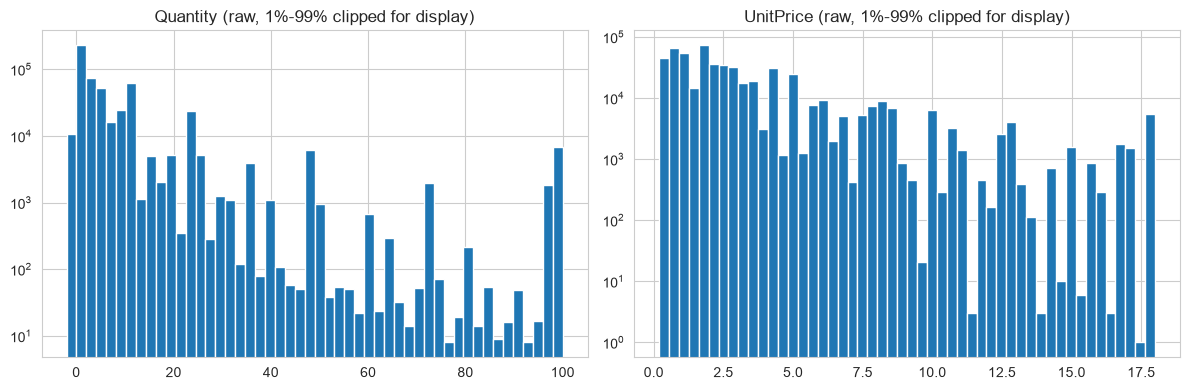

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, numeric_raw):
    s = df_raw[c].clip(lower=df_raw[c].quantile(0.01), upper=df_raw[c].quantile(0.99))
    s.hist(ax=ax, bins=50)
    ax.set_title(f"{c} (raw, 1%-99% clipped for display)")
    ax.set_yscale("log")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/du_hist_raw.png", dpi=120)
plt.show()

سؤال ۱۲: Boxplot برای تمام ویژگی‌های عددی.


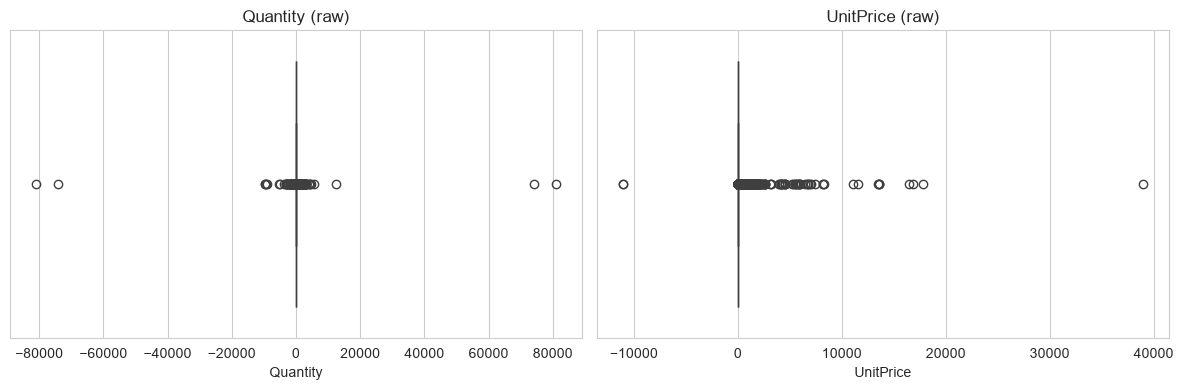

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, numeric_raw):
    sns.boxplot(x=df_raw[c], ax=ax)
    ax.set_title(f"{c} (raw)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/du_box_raw.png", dpi=120)
plt.show()

سؤال ۱۳: KDE Plot برای تمام ویژگی‌های عددی.


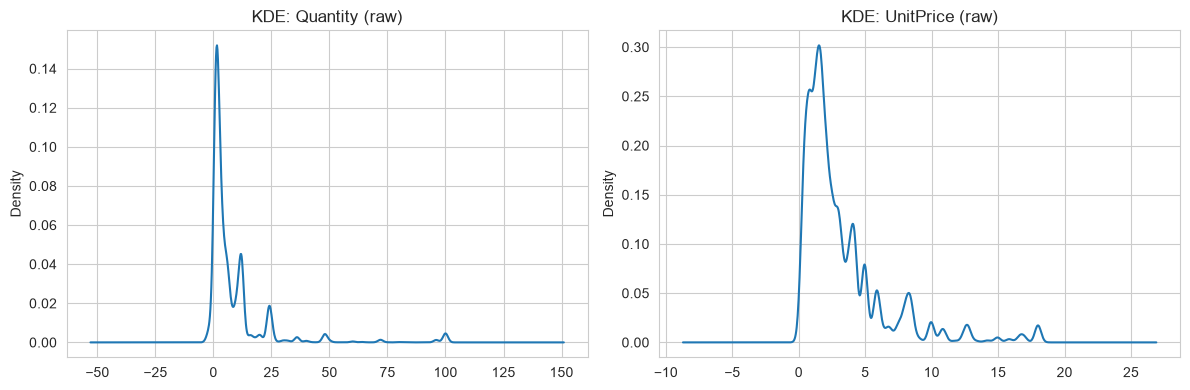

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, numeric_raw):
    s = df_raw[c].clip(lower=df_raw[c].quantile(0.01), upper=df_raw[c].quantile(0.99))
    s.plot.kde(ax=ax)
    ax.set_title(f"KDE: {c} (raw)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/du_kde_raw.png", dpi=120)
plt.show()

سؤال ۱۴: فراوانی تمام ویژگی‌های دسته‌ای.


In [15]:
print("=== Country (top 10) ===")
print(df_raw["Country"].value_counts(dropna=False).head(10))
print(f"\nTotal countries: {df_raw['Country'].nunique(dropna=True)}")

print("\n=== شناسه‌ها (خلاصه) ===")
for c in ["InvoiceNo", "StockCode", "CustomerID"]:
    print(f"{c}: {df_raw[c].nunique(dropna=True):,} یکتا")

=== Country (top 10) ===
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Total countries: 38

=== شناسه‌ها (خلاصه) ===
InvoiceNo: 25,900 یکتا
StockCode: 4,070 یکتا
CustomerID: 4,372 یکتا
